# Paper 2: A Confidence-Driven Adaptive Multi-Sensor Fusion Framework for Robust Autonomous Vehicle Localization

## Notebook 02 – Dataset Exploration

### Objective

This notebook performs an in-depth exploration of the KITTI Odometry dataset before sensor preprocessing.

The notebook includes:

- Dataset overview
- Sequence statistics
- Camera calibration analysis
- Image resolution verification
- Ground truth trajectory visualization
- Translation statistics
- Rotation statistics
- Publication-quality figures

The outputs generated in this notebook will be directly used in the methodology and experimental sections of the research paper.

In [1]:
import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D

plt.style.use("default")

plt.rcParams["figure.figsize"] = (9,6)
plt.rcParams["figure.dpi"] = 150

In [2]:
ROOT_DIR = Path(r"D:\Research\Papers\Paper_2\datasets\KITTI_Odometry")

COLOR_DIR = ROOT_DIR / "data_odometry_color" / "dataset" / "sequences"

CALIB_DIR = ROOT_DIR / "data_odometry_calib" / "dataset" / "sequences"

POSE_DIR = ROOT_DIR / "data_odometry_poses" / "dataset" / "poses"

RESULT_DIR = Path("../results/dataset_exploration")

FIGURE_DIR = Path("../figures/dataset_exploration")

RESULT_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
sequence_dirs = sorted(
    [d.name for d in COLOR_DIR.iterdir() if d.is_dir()]
)

dataset_info = []

for seq in sequence_dirs:

    image_folder = COLOR_DIR / seq / "image_2"

    num_images = len(list(image_folder.glob("*.png")))

    dataset_info.append({

        "Sequence": seq,

        "Frames": num_images,

        "Ground Truth": (POSE_DIR / f"{seq}.txt").exists()

    })

overview_df = pd.DataFrame(dataset_info)

display(overview_df)

,Sequence,Frames,Ground Truth
0,00,4541,True
1,01,1101,True
2,02,4661,True
3,03,801,True
4,04,271,True
5,05,2761,True
6,06,1101,True
7,07,1101,True
8,08,4071,True
9,09,1591,True


In [4]:
summary = pd.DataFrame({

    "Property":[

        "Dataset",

        "Total Sequences",

        "Training Sequences",

        "Testing Sequences",

        "Total Frames"

    ],

    "Value":[

        "KITTI Odometry",

        len(overview_df),

        overview_df["Ground Truth"].sum(),

        len(overview_df)-overview_df["Ground Truth"].sum(),

        overview_df["Frames"].sum()

    ]

})

display(summary)

,Property,Value
0,Dataset,KITTI Odometry
1,Total Sequences,22
2,Training Sequences,11
3,Testing Sequences,11
4,Total Frames,43552


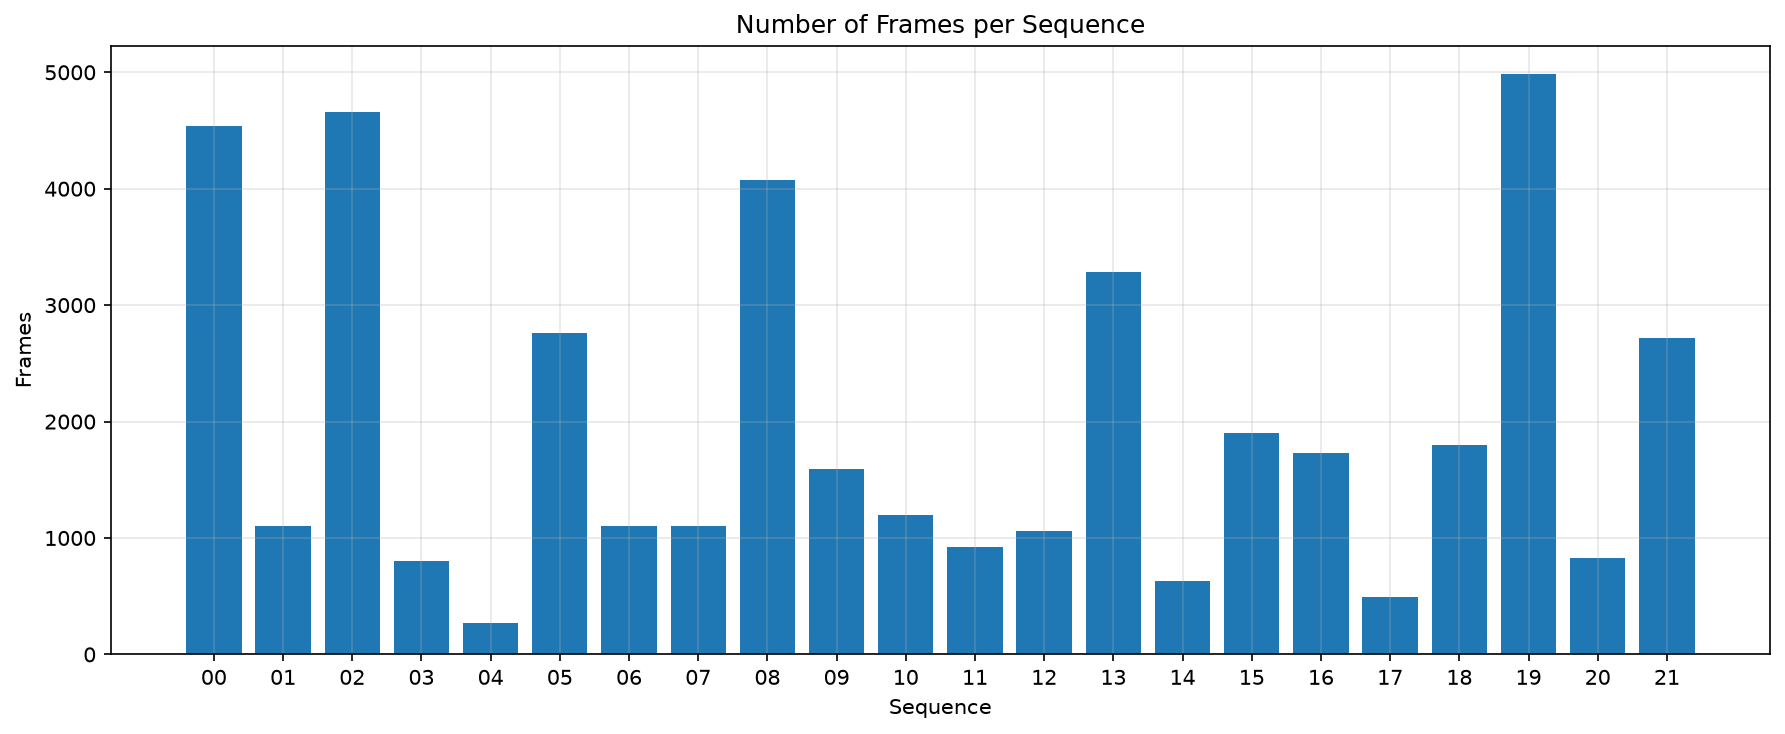

In [5]:
plt.figure(figsize=(12,5))

plt.bar(

    overview_df["Sequence"],

    overview_df["Frames"]

)

plt.title("Number of Frames per Sequence")

plt.xlabel("Sequence")

plt.ylabel("Frames")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR/"frames_per_sequence.png",
    dpi=300
)

plt.show()

In [6]:
sample = COLOR_DIR/"00"/"image_2"/"000000.png"

img = cv2.imread(str(sample))

h,w = img.shape[:2]

print("Width :",w)

print("Height:",h)

Width : 1241
Height: 376


In [7]:
calib_file = CALIB_DIR/"00"/"calib.txt"

with open(calib_file,"r") as f:

    lines = f.readlines()

for line in lines:

    print(line.strip())

P0: 7.188560000000e+02 0.000000000000e+00 6.071928000000e+02 0.000000000000e+00 0.000000000000e+00 7.188560000000e+02 1.852157000000e+02 0.000000000000e+00 0.000000000000e+00 0.000000000000e+00 1.000000000000e+00 0.000000000000e+00
P1: 7.188560000000e+02 0.000000000000e+00 6.071928000000e+02 -3.861448000000e+02 0.000000000000e+00 7.188560000000e+02 1.852157000000e+02 0.000000000000e+00 0.000000000000e+00 0.000000000000e+00 1.000000000000e+00 0.000000000000e+00
P2: 7.188560000000e+02 0.000000000000e+00 6.071928000000e+02 4.538225000000e+01 0.000000000000e+00 7.188560000000e+02 1.852157000000e+02 -1.130887000000e-01 0.000000000000e+00 0.000000000000e+00 1.000000000000e+00 3.779761000000e-03
P3: 7.188560000000e+02 0.000000000000e+00 6.071928000000e+02 -3.372877000000e+02 0.000000000000e+00 7.188560000000e+02 1.852157000000e+02 2.369057000000e+00 0.000000000000e+00 0.000000000000e+00 1.000000000000e+00 4.915215000000e-03
Tr: 4.276802385584e-04 -9.999672484946e-01 -8.084491683471e-03 -1.198

In [8]:
poses = pd.read_csv(

    POSE_DIR/"00.txt",

    sep=" ",

    header=None

)

poses.columns=[

    "r11","r12","r13","tx",

    "r21","r22","r23","ty",

    "r31","r32","r33","tz"

]

poses.head()

,r11,r12,r13,tx,r21,r22,r23,ty,r31,r32,r33,tz
0,1.000000,9.043680e-12,2.326809e-11,5.551115e-17,9.043683e-12,1.000000,2.392370e-10,3.330669e-16,2.326810e-11,2.392370e-10,1.000000,-4.440892e-16
1,0.999998,5.272628e-04,-2.066935e-03,-4.690294e-02,-5.296506e-04,0.999999,-1.154865e-03,-2.839928e-02,2.066324e-03,1.155958e-03,0.999997,8.586941e-01
2,0.999991,1.048972e-03,-4.131348e-03,-9.374345e-02,-1.058514e-03,0.999997,-2.308104e-03,-5.676064e-02,4.128913e-03,2.312456e-03,0.999989,1.716275e+00
3,0.999980,1.566466e-03,-6.198571e-03,-1.406429e-01,-1.587952e-03,0.999993,-3.462706e-03,-8.515762e-02,6.193102e-03,3.472479e-03,0.999975,2.574964e+00
4,0.999964,2.078471e-03,-8.263498e-03,-1.874858e-01,-2.116664e-03,0.999987,-4.615826e-03,-1.135202e-01,8.253797e-03,4.633149e-03,0.999955,3.432648e+00


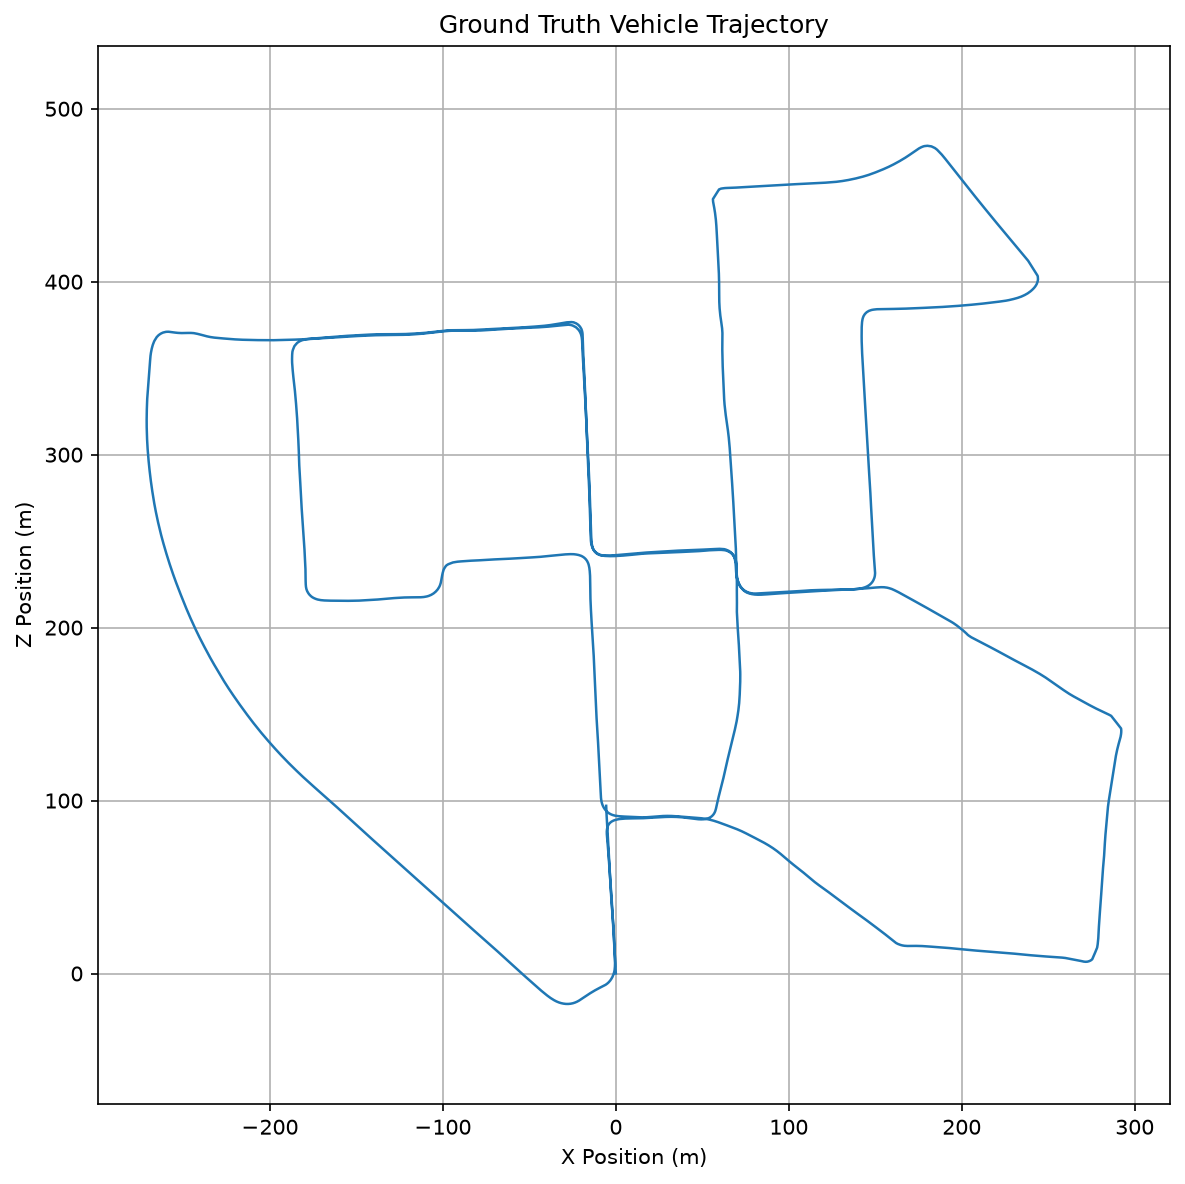

In [9]:
plt.figure(figsize=(8,8))

plt.plot(

    poses["tx"],

    poses["tz"],

    linewidth=1.2

)

plt.xlabel("X Position (m)")

plt.ylabel("Z Position (m)")

plt.title("Ground Truth Vehicle Trajectory")

plt.axis("equal")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR/"trajectory_2D.png",

    dpi=300

)

plt.show()

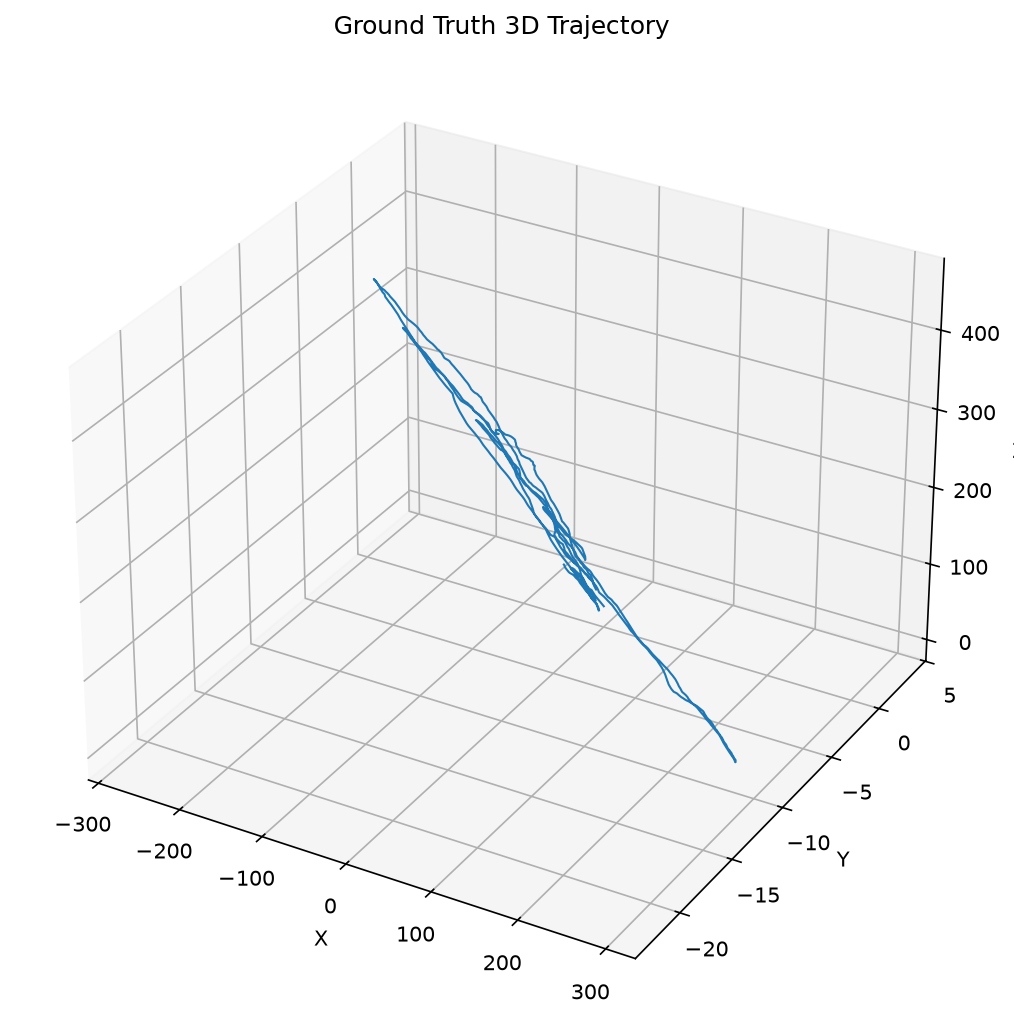

In [10]:
fig = plt.figure(figsize=(9,7))

ax = fig.add_subplot(111,projection="3d")

ax.plot(

    poses["tx"],

    poses["ty"],

    poses["tz"],

    linewidth=1

)

ax.set_xlabel("X")

ax.set_ylabel("Y")

ax.set_zlabel("Z")

ax.set_title("Ground Truth 3D Trajectory")

plt.tight_layout()

plt.savefig(

    FIGURE_DIR/"trajectory_3D.png",

    dpi=300

)

plt.show()

In [11]:
translation_stats = poses[["tx", "ty", "tz"]].describe().T

display(translation_stats)

translation_stats.to_csv(
    RESULT_DIR / "translation_statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max
tx,4541.0,22.378433,142.014459,-271.28060,-59.75404,10.714580,132.663600,292.239500
ty,4541.0,-7.904195,6.214197,-22.29466,-12.01166,-7.488594,-3.079246,3.225534
tz,4541.0,230.699902,131.487950,-17.60491,116.29990,238.441600,359.411700,478.591500


In [12]:
rotation_stats = poses[
    [
        "r11","r12","r13",
        "r21","r22","r23",
        "r31","r32","r33"
    ]
].describe().T

display(rotation_stats)

rotation_stats.to_csv(
    RESULT_DIR/"rotation_statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max
r11,4541.0,0.077408,0.691782,-0.999939,-0.584706,-0.012153,0.895636,1.000000
r12,4541.0,0.034070,0.024297,-0.066186,0.016139,0.033974,0.053932,0.093741
r13,4541.0,-0.012741,0.716764,-0.999054,-0.875506,-0.002484,0.741525,0.999995
r21,4541.0,0.009753,0.041641,-0.081747,-0.023489,0.005515,0.038189,0.110780
r22,4541.0,0.998450,0.001302,0.993258,0.997797,0.998734,0.999506,1.000000
r23,4541.0,0.014748,0.032392,-0.063186,-0.015162,0.011974,0.046702,0.080471
r31,4541.0,0.013595,0.716694,-0.999984,-0.737556,0.003846,0.875843,0.999993
r32,4541.0,0.027745,0.023971,-0.042095,0.011747,0.027725,0.044813,0.087402
r33,4541.0,0.077477,0.692124,-0.999227,-0.584576,-0.010953,0.895550,1.000000


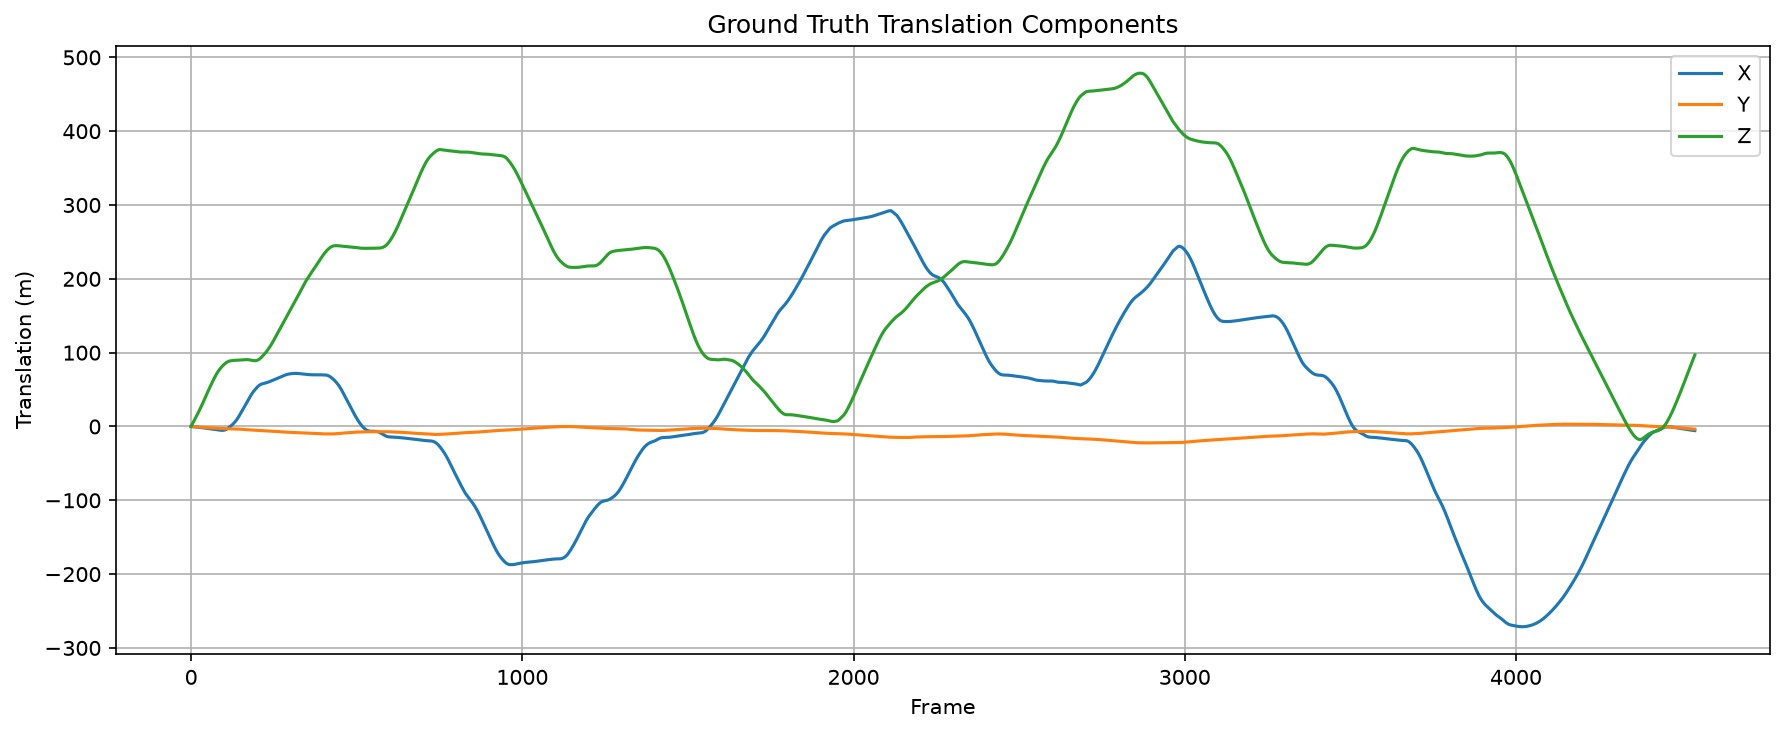

In [13]:
plt.figure(figsize=(12,5))

plt.plot(
    poses["tx"],
    label="X"
)

plt.plot(
    poses["ty"],
    label="Y"
)

plt.plot(
    poses["tz"],
    label="Z"
)

plt.xlabel("Frame")

plt.ylabel("Translation (m)")

plt.title("Ground Truth Translation Components")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR/"translation_components.png",
    dpi=300
)

plt.show()

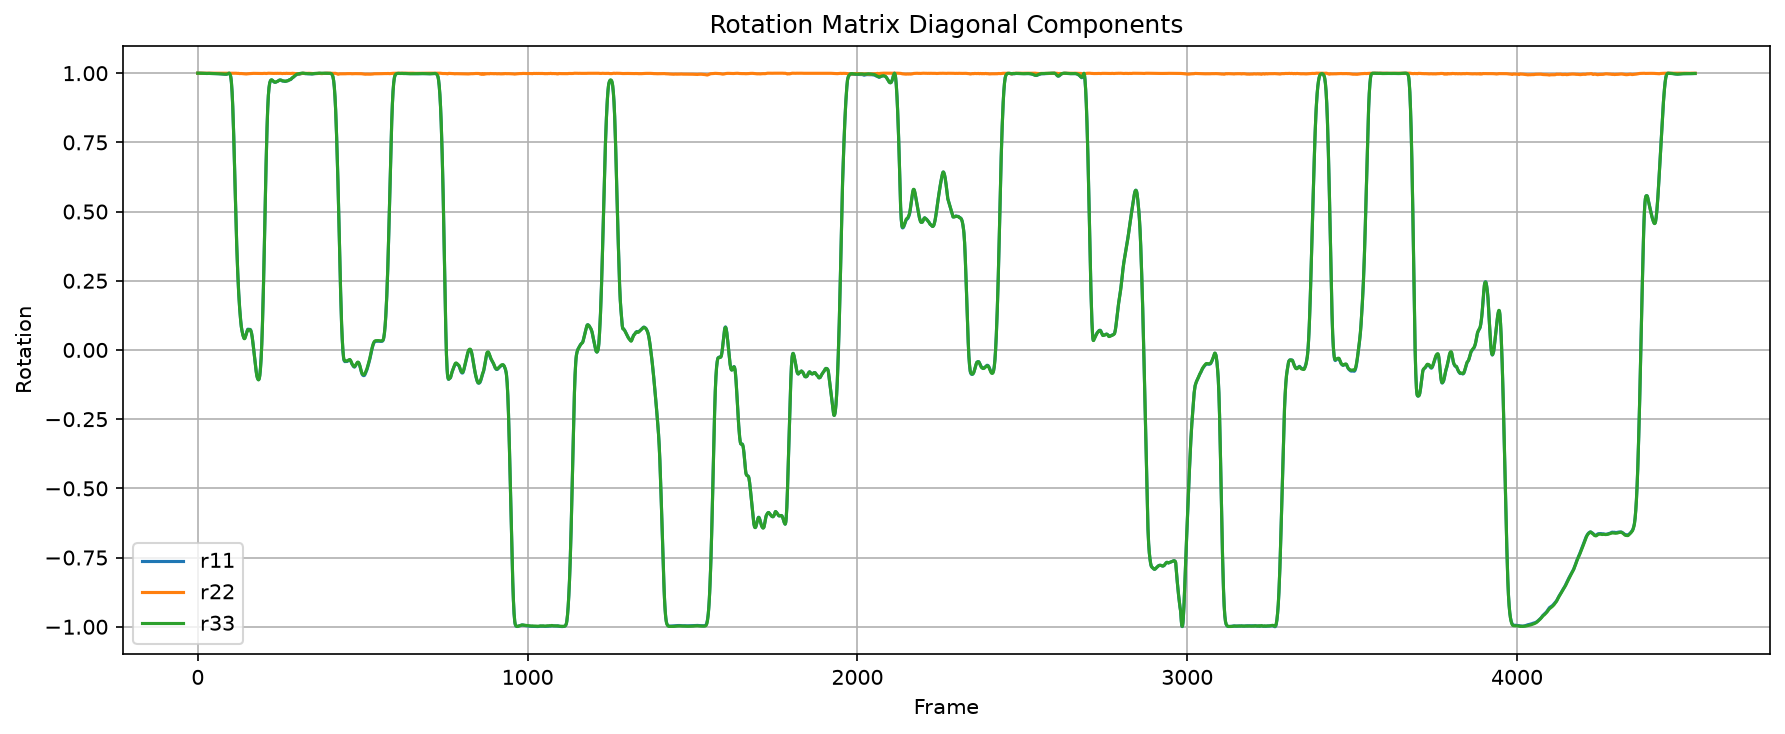

In [14]:
plt.figure(figsize=(12,5))

plt.plot(poses["r11"],label="r11")
plt.plot(poses["r22"],label="r22")
plt.plot(poses["r33"],label="r33")

plt.xlabel("Frame")

plt.ylabel("Rotation")

plt.title("Rotation Matrix Diagonal Components")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR/"rotation_components.png",
    dpi=300
)

plt.show()

In [15]:
xyz = poses[["tx","ty","tz"]].values

distance = np.linalg.norm(
    np.diff(xyz, axis=0),
    axis=1
)

trajectory_length = distance.sum()

print(f"Trajectory Length : {trajectory_length:.2f} meters")

Trajectory Length : 3724.19 meters


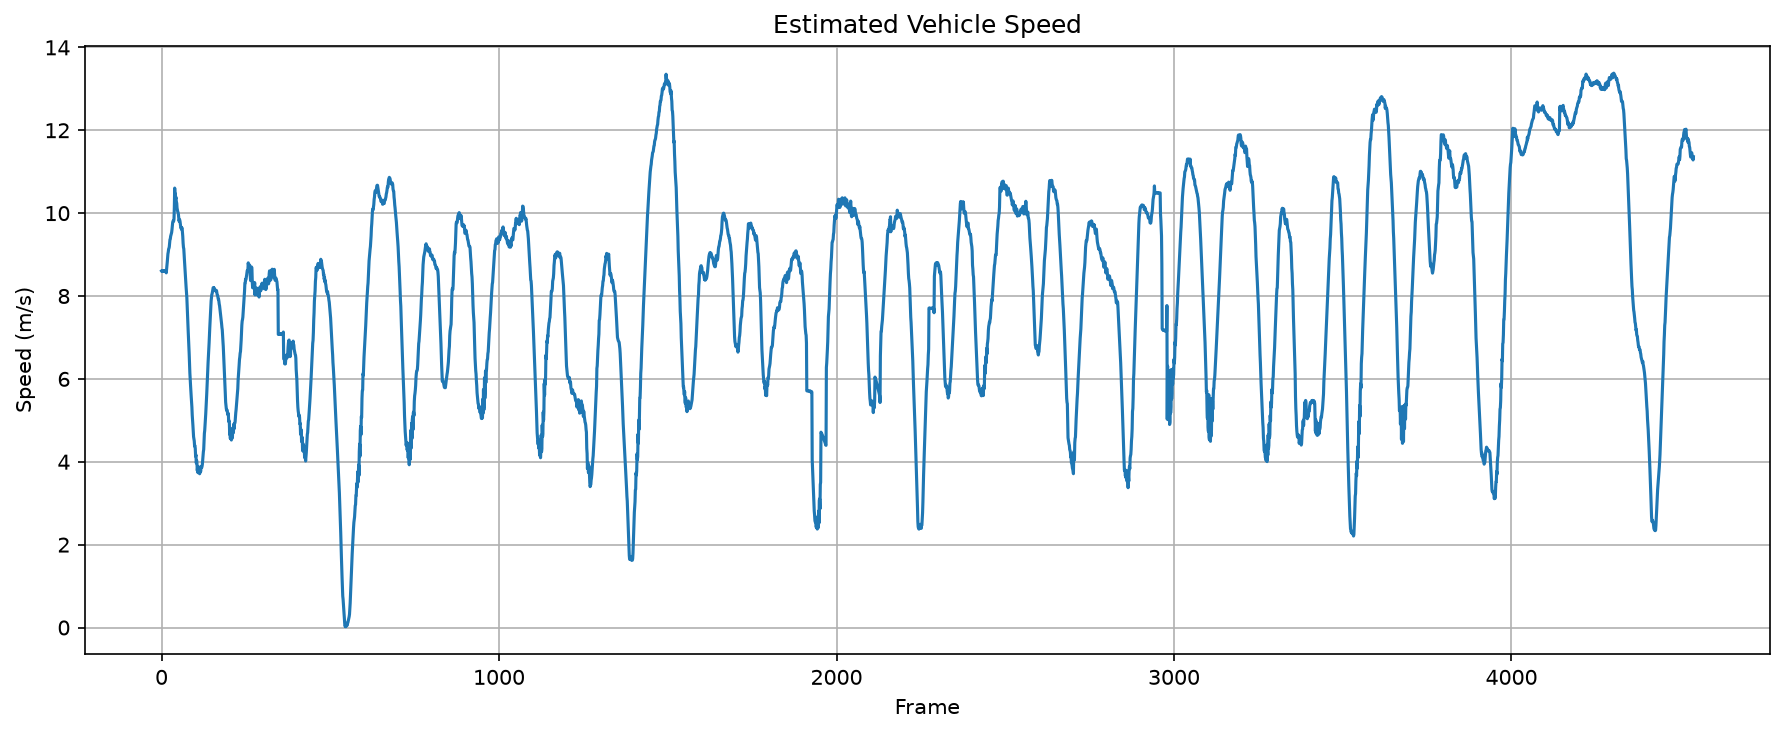

In [16]:
FRAME_RATE = 10

speed = distance * FRAME_RATE

plt.figure(figsize=(12,5))

plt.plot(speed)

plt.title("Estimated Vehicle Speed")

plt.xlabel("Frame")

plt.ylabel("Speed (m/s)")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR/"vehicle_speed.png",
    dpi=300
)

plt.show()

In [17]:
speed_df = pd.DataFrame({
    "Speed (m/s)": speed
})

display(speed_df.describe())

,Speed (m/s)
count,4540.000000
mean,8.203055
std,2.706557
min,0.018501
25%,6.081330
50%,8.530177
75%,10.109634
max,13.377369


## Dataset Insights

The exploration of the KITTI Odometry dataset reveals the following:

- The benchmark consists of **22 driving sequences**.
- **11 sequences** provide ground-truth trajectories and are used for training and evaluation.
- **11 sequences** are reserved for benchmark testing.
- The dataset contains **43,552 stereo color images**.
- The image resolution is **1241 × 376 pixels**.
- Calibration files are available for every sequence.
- Ground-truth trajectories provide accurate vehicle poses for localization analysis.

These characteristics make the KITTI Odometry benchmark suitable for evaluating adaptive confidence-driven multi-sensor localization methods.